# 03 · Experimento de madurez de datos

**Grupo 2 · Big Data e IA aplicada** · Industria 4.0, FIUNA · Caso Casa Rojas (Fideos Napoli)

**Lo muestra:** Franco · **Escalón 3 y cierre de la exposición**

El notebook 02 midió qué pasa con **todos** los datos. Una pyme no tiene todos los datos: tiene
menos historia, registros que nunca se cargaron o totales mensuales en vez de pedidos. Este
notebook simula esas empresas recortando y degradando el mismo dataset, y responde:

> **¿Desde qué nivel de historia, calidad y frecuencia vale la pena pasar de BI a ML?**

| Sección | Qué hace |
|---|---|
| 1. Diseño | Los nueve escenarios y el criterio, declarado antes de correr |
| 2. Carga | Dataset limpio de 01 y decisiones de la selección de 02 |
| 3. Corrida | El backtest de 6 orígenes en cada escenario |
| 4. Historización | ¿Cuánta historia hace falta? |
| 5. Calidad | ¿Qué pasa si se pierden registros? |
| 6. Frecuencia | ¿Conviene registrar por semana? |
| 7. Criterio | ¿En qué escenarios vale la pena el ML? |
| 8. Respuesta | La respuesta a la pregunta de investigación |

> Para la exposición, dejar `RECALCULAR = False`: los escenarios se releen de `resultados/cache/`.
> Con `True` el experimento tarda del orden de 45 minutos, casi todo en ETS.

In [1]:
# Preparación: el mismo bloque funciona en Google Colab y en local.
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    # Carpeta del repo dentro de Drive. Cambiala si la subiste con otro nombre.
    RAIZ = Path("/content/drive/MyDrive/Industria40")
    import importlib.util

    faltan = [m for m in ('statsforecast',) if importlib.util.find_spec(m) is None]
    if faltan:
        get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(RAIZ / "src"))
print("Repo en:", RAIZ)

Repo en: C:\Users\franc\Desktop\Desk\Projects\Private\Industria40


In [2]:
RECALCULAR = False  # True: vuelve a correr los nueve escenarios. False: relee la caché si existe.

In [3]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda import backtest as B
from demanda import config as cfg
from demanda import datos as D
from demanda import graficos as G
from demanda import metricas as M
from demanda import modelos as Mo

G.estilo()
cfg.asegurar_carpetas()
CACHE = cfg.RESULTADOS / "cache"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
print(f"Python {platform.python_version()} · pandas {pd.__version__}")

Python 3.12.4 · pandas 2.3.3


## 1. Diseño del experimento

Cada escenario repite el mismo backtest: 6 pronósticos de 2016 (febrero, abril, junio, agosto,
octubre y diciembre), cada uno con lo que se sabía dos meses antes, y con los siete modelos de
regresión del notebook 02. Se cambia **un factor por vez**; los demás quedan como en el escenario
base: mensual, historia completa y sin faltantes.

| Factor | Niveles | Cómo se simula |
|---|---|---|
| Historización | 6, 12, 24 y 36 meses, y completa | En cada origen se borra lo anterior a la ventana, antes de calcular variables y entrenar |
| Calidad | 0, 5, 15 y 30 % de registros perdidos | Se borran al azar pedidos del dataset limpio y se rearma el panel. Son ventas que nunca se cargaron |
| Frecuencia | Mensual y semanal | El mes se parte en cuatro semanas (días 1-7, 8-14, 15-21 y 22 a fin de mes); se pronostican las cuatro de `t + 2` y se suman |

La evaluación es **siempre contra la demanda real completa**. Una empresa que no cargó el 15 % de
sus ventas igual tuvo que abastecer esa demanda: el error que importa es contra lo que pasó, no
contra lo que se registró.

### El criterio, declarado antes de mirar los resultados

El ML **vale la pena** en un escenario cuando el mejor modelo de ML (Ridge o LightGBM) cumple las
dos condiciones:

1. su WAPE es al menos **5 % menor** que el de la mejor referencia simple (naive, naive
   estacional, media móvil o Croston), y
2. le gana en al menos **4 de los 6** meses pronosticados.

El 5 % es un supuesto de consultoría: una mejora menor no paga mantener un pipeline en Python y a
alguien que lo entienda. ETS se reporta aparte, como la alternativa estadística.

In [4]:
print(f"Umbral de mejora: {G.pct(cfg.UMBRAL_MEJORA_ML, 0)} · orígenes ganados mínimos: {cfg.ORIGENES_GANADOS_MIN} de {len(cfg.MESES_EXPERIMENTO)}")
print("Meses pronosticados:", ", ".join(str(m) for m in cfg.MESES_EXPERIMENTO))

Umbral de mejora: 5 % · orígenes ganados mínimos: 4 de 6
Meses pronosticados: 2016-02, 2016-04, 2016-06, 2016-08, 2016-10, 2016-12


## 2. Carga

El notebook usa el dataset limpio a nivel de pedido, porque el escenario de calidad borra pedidos
y el de frecuencia los agrupa por semana. La ventana de la media móvil y la pérdida de LightGBM
vienen de la selección en 2015 del notebook 02 y no se vuelven a elegir.

In [5]:
seleccion = json.loads((cfg.TABLAS / "seleccion.json").read_text(encoding="utf-8"))
K_MEDIA, OBJETIVO = seleccion["k_media"], seleccion["objetivo"]
MEDIA = f"Media móvil {K_MEDIA}m"

limpio = D.leer_limpio()
dim = pd.read_parquet(cfg.ARCHIVO_DIM_SERIE)
series = dim[["serie", "producto", "deposito", "categoria"]]
assert (series["serie"].to_numpy() == D.catalogo_series(limpio)["serie"].to_numpy()).all()

mensual = D.armar_panel(limpio, series=series)
verdad = mensual.Y
semanal = D.armar_panel(limpio, p=4, series=series)
assert np.allclose(np.nan_to_num(semanal.mensual()), np.nan_to_num(verdad)), "las semanas tienen que sumar el mes"

print(f"Media móvil de {K_MEDIA} meses y LightGBM con pérdida {OBJETIVO.upper()}, elegidos en 2015 (notebook 02)")
print(f"Panel mensual {mensual.Y.shape} · panel semanal {semanal.Y.shape}")

Media móvil de 12 meses y LightGBM con pérdida L1, elegidos en 2015 (notebook 02)
Panel mensual (2849, 60) · panel semanal (2849, 240)


### La pérdida de LightGBM en semanal

La selección de 02 se hizo con datos mensuales. Con datos semanales la pregunta cambia: la L1
estima la **mediana** de cada semana, y la suma de cuatro medianas no es la mediana del mes; en
semanas con muchos ceros queda muy por debajo. Para no castigar a la frecuencia semanal con una
decisión tomada para otra, se repite la misma selección, con la misma regla y en 2015, sobre el
panel semanal.

In [6]:
candidatos_semanal = [Mo.LightGBM("l1", nombre="LightGBM L1"), Mo.LightGBM("l2", nombre="LightGBM L2")]
pred_sel_sem = B.con_cache(
    CACHE / "exp_seleccion_semanal.parquet",
    RECALCULAR,
    lambda: B.correr(semanal, verdad, cfg.MESES_SELECCION, candidatos_semanal, k_respaldo=K_MEDIA, etiqueta="Selección semanal"),
)
r = B.evaluar(pred_sel_sem)[1].set_index("modelo")
l1, l2 = r.loc["LightGBM L1"], r.loc["LightGBM L2"]
if abs(l1["wape"] - l2["wape"]) / min(l1["wape"], l2["wape"]) < 0.01:
    OBJETIVO_SEMANAL = "l1" if abs(l1["sesgo"]) <= abs(l2["sesgo"]) else "l2"
else:
    OBJETIVO_SEMANAL = "l1" if l1["wape"] < l2["wape"] else "l2"
print(f"Semanal · L1: WAPE {G.pct(l1['wape'])}, sesgo {G.pct(l1['sesgo'])} · L2: WAPE {G.pct(l2['wape'])}, sesgo {G.pct(l2['sesgo'])}")
print(f"Pérdida elegida para semanal: {OBJETIVO_SEMANAL.upper()}")

Leído de la caché: exp_seleccion_semanal.parquet


Semanal · L1: WAPE 39,5 %, sesgo -25,8 % · L2: WAPE 37,5 %, sesgo 3,8 %
Pérdida elegida para semanal: L2


## 3. Corrida

Cada escenario se guarda en la caché apenas termina, así que una corrida interrumpida retoma desde
el escenario que faltaba.

In [7]:
ESCENARIOS = [
    {"id": "base", "factor": "Base", "nivel": "Completa", "etiqueta": "Base: mensual, historia completa, sin faltantes"},
    *[
        {"id": f"historia_{h}", "factor": "Historización", "nivel": h, "etiqueta": f"{h} meses de historia", "historia": h}
        for h in cfg.HISTORIAS_MESES
    ],
    *[
        {"id": f"faltantes_{round(f * 100)}", "factor": "Calidad", "nivel": f, "etiqueta": f"{round(f * 100)} % de registros perdidos", "faltante": f}
        for f in cfg.FALTANTES
    ],
    {"id": "semanal", "factor": "Frecuencia", "nivel": "Semanal", "etiqueta": "Datos semanales", "p": 4},
]


def correr_escenario(esc):
    """Arma lo que la empresa del escenario habría registrado y corre el backtest."""
    if "faltante" in esc:
        registrado, objetivo = D.armar_panel(D.degradar(limpio, esc["faltante"]), series=series), OBJETIVO
    elif esc.get("p") == 4:
        registrado, objetivo = semanal, OBJETIVO_SEMANAL
    else:
        registrado, objetivo = mensual, OBJETIVO
    return B.correr(
        registrado,
        verdad,
        cfg.MESES_EXPERIMENTO,
        Mo.modelos_regresion(K_MEDIA, objetivo),
        historia_meses=esc.get("historia"),
        k_respaldo=K_MEDIA,
        etiqueta=esc["etiqueta"],
    )


preds = []
for esc in ESCENARIOS:
    p = B.con_cache(CACHE / f"exp_{esc['id']}.parquet", RECALCULAR, lambda esc=esc: correr_escenario(esc))
    preds.append(p.assign(escenario=esc["id"]))
pred = pd.concat(preds, ignore_index=True)
print(f"{G.num(len(pred))} pronósticos evaluados en {len(ESCENARIOS)} escenarios")

Leído de la caché: exp_base.parquet


Leído de la caché: exp_historia_6.parquet


Leído de la caché: exp_historia_12.parquet


Leído de la caché: exp_historia_24.parquet


Leído de la caché: exp_historia_36.parquet


Leído de la caché: exp_faltantes_5.parquet


Leído de la caché: exp_faltantes_15.parquet


Leído de la caché: exp_faltantes_30.parquet


Leído de la caché: exp_semanal.parquet


1.072.260 pronósticos evaluados en 9 escenarios


In [8]:
po, res = B.evaluar(pred, claves=("escenario", "modelo"))
ORDEN = [m.nombre for m in Mo.modelos_regresion(K_MEDIA, OBJETIVO)]
REFERENCIAS = ["Naive", "Naive estacional", MEDIA, "Croston SBA"]
ML = ["Ridge", "LightGBM"]

# Un modelo que no se pudo aplicar a la mitad de las series no se reporta en ese escenario.
no_aplica = res["aplica"] < B.MIN_APLICA
res.loc[no_aplica, ["wape", "wape_desvio", "wape_peor", "sesgo", "mase", "mae"]] = np.nan
info = pd.DataFrame(ESCENARIOS).set_index("id")
res = res.join(info[["factor", "nivel", "etiqueta"]], on="escenario")
res.to_csv(cfg.TABLAS / "experimento_metricas.csv", index=False)

print("No aplica en:", ", ".join(f"{m} con {info.loc[e, 'etiqueta']}" for e, m in res.loc[no_aplica, ["escenario", "modelo"]].itertuples(index=False)) or "ninguno")


def tabla(ids, columnas, metrica="wape"):
    t = res[res["escenario"].isin(ids)].pivot(index="modelo", columns="escenario", values=metrica)[ids].loc[ORDEN]
    t.columns = columnas
    return t

No aplica en: Naive estacional con 6 meses de historia, ETS con 6 meses de historia


## 4. Historización: ¿cuánta historia hace falta?

«Completa» son todos los datos desde enero de 2012: entre 47 y 57 meses según el mes pronosticado.

,6,12,24,36,Completa
modelo,,,,,
Naive,"43,6 %","43,6 %","43,6 %","43,6 %","43,6 %"
Naive estacional,no aplica,"53,1 %","53,1 %","53,1 %","53,1 %"
Media móvil 12m,"36,9 %","38,4 %","38,4 %","38,4 %","38,4 %"
Croston SBA,"40,9 %","40,4 %","38,8 %","38,5 %","38,5 %"
ETS,no aplica,"37,6 %","37,9 %","39,6 %","39,8 %"
Ridge,"49,8 %","43,8 %","57,9 %","37,0 %","37,0 %"
LightGBM,"35,6 %","34,2 %","34,5 %","34,4 %","34,1 %"


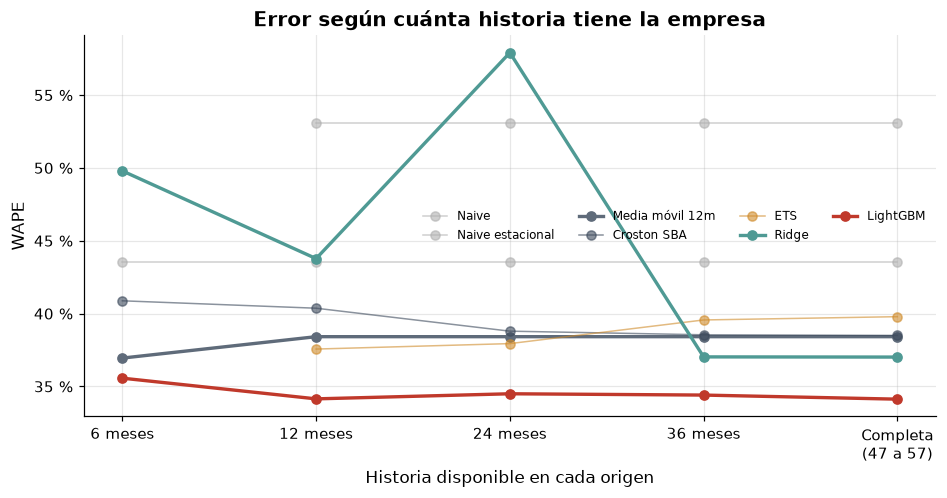

In [9]:
ids_hist = [f"historia_{h}" for h in cfg.HISTORIAS_MESES] + ["base"]
etiquetas_hist = [str(h) for h in cfg.HISTORIAS_MESES] + ["Completa"]
t_hist = tabla(ids_hist, etiquetas_hist)
display(t_hist.map(lambda v: "no aplica" if pd.isna(v) else G.pct(v)))

fig, ax = plt.subplots()
x = np.arange(len(ids_hist))
for m in ORDEN:
    destacado = m in ML or m == MEDIA
    ax.plot(x, t_hist.loc[m].to_numpy(), marker="o", color=G.color(m), lw=2.2 if destacado else 1, alpha=1 if destacado else 0.6, label=m)
ax.set_xticks(x, ["6 meses", "12 meses", "24 meses", "36 meses", "Completa\n(47 a 57)"])
G.porcentaje(ax)
ax.set_ylabel("WAPE")
ax.set_xlabel("Historia disponible en cada origen")
ax.set_title("Error según cuánta historia tiene la empresa")
ax.legend(ncol=4, fontsize=8)
G.guardar(fig, "03_historia_wape")
plt.show()

In [10]:
for i, etiqueta in zip(ids_hist, etiquetas_hist):
    r = res[(res["escenario"] == i)].set_index("modelo")
    mejor_ref = r.loc[REFERENCIAS, "wape"].idxmin()
    mejor_ml = r.loc[ML, "wape"].idxmin()
    print(f"{etiqueta:>8}: mejor referencia {mejor_ref} {G.pct(r.loc[mejor_ref, 'wape'])} · mejor ML {mejor_ml} {G.pct(r.loc[mejor_ml, 'wape'])}")

       6: mejor referencia Media móvil 12m 36,9 % · mejor ML LightGBM 35,6 %
      12: mejor referencia Media móvil 12m 38,4 % · mejor ML LightGBM 34,2 %
      24: mejor referencia Media móvil 12m 38,4 % · mejor ML LightGBM 34,5 %
      36: mejor referencia Media móvil 12m 38,4 % · mejor ML LightGBM 34,4 %
Completa: mejor referencia Media móvil 12m 38,4 % · mejor ML LightGBM 34,1 %


**Qué nos dice esto.**

- Con poca historia algunos métodos directamente **no se pueden usar**. Sin un año completo no
  existe «el mismo mes del año anterior», y ETS no tiene con qué estimar sus parámetros. La media
  móvil funciona desde el primer mes, y por eso es la regla natural de una empresa que recién
  empieza a registrar.
- **LightGBM es estable** en todos los niveles: pierde poco al pasar de la historia completa a 12
  meses, y recién con 6 meses su ventaja se achica.
- **Ridge es inestable con la historia recortada**, y no mejora de forma pareja al tener más
  historia. Es un problema real de los modelos lineales, no del experimento: en una empresa con 24
  meses de registros, los ejemplos más viejos del entrenamiento no tienen todavía el mismo mes de
  dos años antes y la prueba sí lo tiene. LightGBM aprende qué hacer cuando falta un dato; Ridge
  lo reemplaza por un valor típico y extrapola en línea recta. Con historia corta, un modelo de
  árboles es más seguro que uno lineal.

## 5. Calidad: ¿qué pasa si se pierden registros?

Los pedidos se borran al azar: es el mejor caso posible de pérdida, porque no favorece a ningún
producto ni a ningún mes. En una empresa real las pérdidas suelen concentrarse (un vendedor que no
carga, un depósito que anota en papel), y el efecto sería peor.

WAPE


,0 %,5 %,15 %,30 %
modelo,,,,
Naive,"43,6 %","43,4 %","44,0 %","50,3 %"
Naive estacional,"53,1 %","52,1 %","52,7 %","56,3 %"
Media móvil 12m,"38,4 %","37,5 %","38,4 %","44,4 %"
Croston SBA,"38,5 %","38,5 %","40,4 %","46,7 %"
ETS,"39,8 %","38,2 %","38,9 %","44,2 %"
Ridge,"37,0 %","37,5 %","39,5 %","46,3 %"
LightGBM,"34,1 %","34,7 %","37,6 %","46,5 %"


Sesgo


,0 %,5 %,15 %,30 %
modelo,,,,
Naive,"2,0 %","-3,6 %","-14,0 %","-28,5 %"
Naive estacional,"11,9 %","6,4 %","-6,3 %","-22,3 %"
Media móvil 12m,"7,7 %","2,3 %","-9,1 %","-24,6 %"
Croston SBA,"3,2 %","-2,0 %","-12,7 %","-27,7 %"
ETS,"10,8 %","5,8 %","-6,5 %","-23,0 %"
Ridge,"-0,8 %","-5,6 %","-15,9 %","-29,6 %"
LightGBM,"-7,2 %","-12,7 %","-22,8 %","-37,8 %"


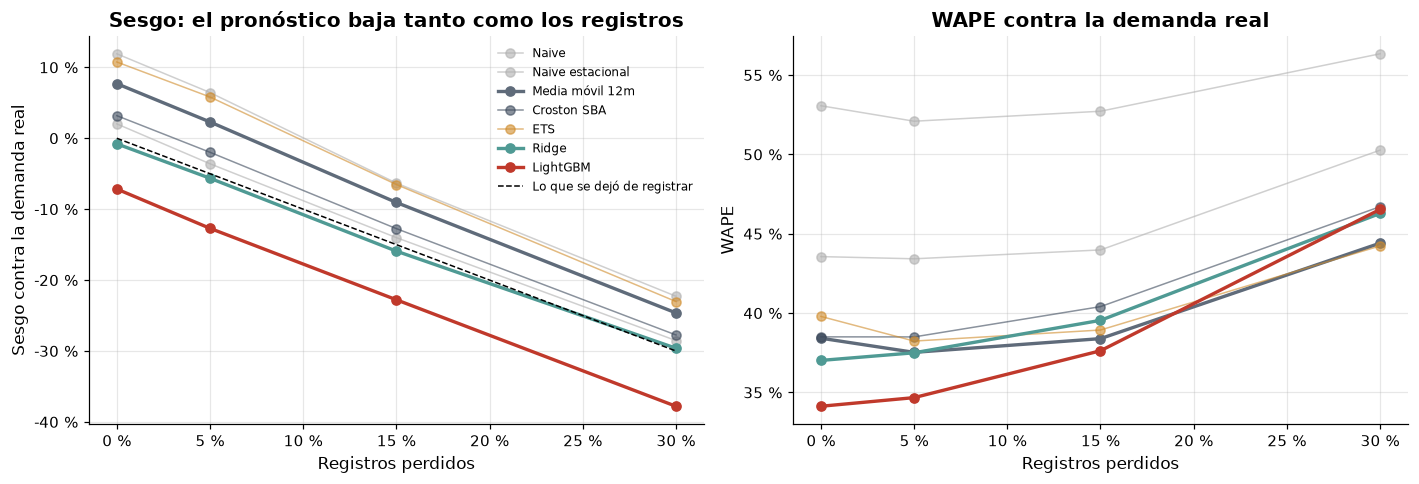

In [11]:
ids_cal = ["base"] + [f"faltantes_{round(f * 100)}" for f in cfg.FALTANTES]
niveles_cal = [0.0] + list(cfg.FALTANTES)
etiquetas_cal = [G.pct(f, 0) for f in niveles_cal]
t_cal_wape = tabla(ids_cal, etiquetas_cal)
t_cal_sesgo = tabla(ids_cal, etiquetas_cal, "sesgo")
print("WAPE")
display(t_cal_wape.map(G.pct))
print("Sesgo")
display(t_cal_sesgo.map(G.pct))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for m in ORDEN:
    destacado = m in ML or m == MEDIA
    kw = dict(marker="o", color=G.color(m), lw=2.2 if destacado else 1, alpha=1 if destacado else 0.6, label=m)
    a1.plot(niveles_cal, t_cal_sesgo.loc[m].to_numpy(), **kw)
    a2.plot(niveles_cal, t_cal_wape.loc[m].to_numpy(), **kw)
a1.plot([0, max(niveles_cal)], [0, -max(niveles_cal)], color="black", ls="--", lw=1, label="Lo que se dejó de registrar")
a1.set_title("Sesgo: el pronóstico baja tanto como los registros")
a1.set_ylabel("Sesgo contra la demanda real")
a2.set_title("WAPE contra la demanda real")
a2.set_ylabel("WAPE")
for a in (a1, a2):
    G.porcentaje(a, "x")
    G.porcentaje(a, "y")
    a.set_xlabel("Registros perdidos")
a1.legend(fontsize=8)
fig.tight_layout()
G.guardar(fig, "03_calidad")
plt.show()

In [12]:
base = res[res["escenario"] == "base"].set_index("modelo")
mejor_base = base.loc[ML + REFERENCIAS, "wape"].idxmin()
ganancia_ml = base.loc[REFERENCIAS, "wape"].min() - base.loc[ML, "wape"].min()
print(f"Lo que gana el ML sobre la mejor referencia, con datos completos: {G.puntos(ganancia_ml)} de WAPE")
costo_faltantes = {}
for f in cfg.FALTANTES:
    r = res[res["escenario"] == f"faltantes_{round(f * 100)}"].set_index("modelo")
    mejor_f = r.loc[ML + REFERENCIAS, "wape"].idxmin()
    costo_faltantes[f] = r.loc[mejor_f, "wape"] - base.loc[mejor_base, "wape"]
    veces = f" ({G.num(costo_faltantes[f] / ganancia_ml, 1)} veces lo que gana el ML)" if ganancia_ml > 0 else ""
    print(
        f"Perder el {G.pct(f, 0)} de los registros: el mejor modelo ({mejor_f}) empeora {G.puntos(costo_faltantes[f])} de WAPE{veces}; "
        f"su sesgo es {G.pct(r.loc[mejor_f, 'sesgo'])}"
    )

Lo que gana el ML sobre la mejor referencia, con datos completos: 4,3 puntos de WAPE
Perder el 5 % de los registros: el mejor modelo (LightGBM) empeora 0,5 puntos de WAPE (0,1 veces lo que gana el ML); su sesgo es -12,7 %
Perder el 15 % de los registros: el mejor modelo (LightGBM) empeora 3,5 puntos de WAPE (0,8 veces lo que gana el ML); su sesgo es -22,8 %
Perder el 30 % de los registros: el mejor modelo (Media móvil 12m) empeora 10,3 puntos de WAPE (2,4 veces lo que gana el ML); su sesgo es -24,6 %


**Qué nos dice esto.** Ningún modelo detecta ventas que no se registraron: todos aprenden una
demanda más baja y pronostican de menos, más o menos en la misma proporción que lo perdido. El
algoritmo no arregla la falta de registro. La comparación que importa para una pyme está en la
celda anterior: cuánto error agrega perder registros, al lado de cuánto error quita el ML.

## 6. Frecuencia: ¿conviene registrar por semana?

La decisión sigue siendo mensual. La pregunta es si tener los pedidos agrupados por semana, en vez
de solo el total del mes, mejora el pronóstico del mes.

WAPE           Sesgo        
                 Mensual Semanal Mensual Semanal
modelo                                          
Naive             43,6 %  78,9 %   2,0 %  20,2 %
Naive estacional  53,1 %  53,1 %  11,9 %  11,9 %
Media móvil 12m   38,4 %  38,4 %   7,7 %   7,7 %
Croston SBA       38,5 %  37,2 %   3,2 %   1,6 %
ETS               39,8 %  39,4 %  10,8 %   9,9 %
Ridge             37,0 %  36,4 %  -0,8 %  -1,8 %
LightGBM          34,1 %  35,6 %  -7,2 %  -0,1 %

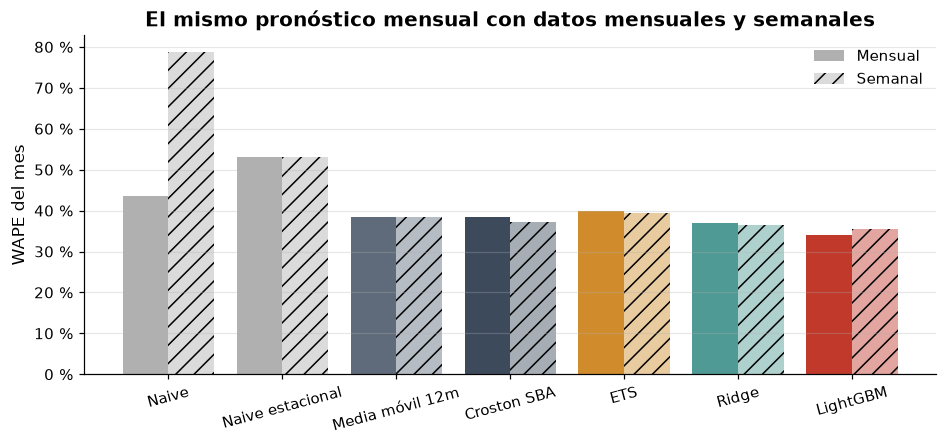

             Naive: empeora 35,3 puntos de WAPE con datos semanales
  Naive estacional: igual con datos semanales
   Media móvil 12m: igual con datos semanales
       Croston SBA: mejora 1,3 puntos de WAPE con datos semanales
               ETS: mejora 0,3 puntos de WAPE con datos semanales
             Ridge: mejora 0,6 puntos de WAPE con datos semanales
          LightGBM: empeora 1,4 puntos de WAPE con datos semanales


In [13]:
t_frec = tabla(["base", "semanal"], ["Mensual", "Semanal"])
t_frec_sesgo = tabla(["base", "semanal"], ["Mensual", "Semanal"], "sesgo")
display(pd.concat({"WAPE": t_frec, "Sesgo": t_frec_sesgo}, axis=1).map(G.pct))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ORDEN))
ax.bar(x - 0.2, t_frec["Mensual"], width=0.4, color=[G.color(m) for m in ORDEN], label="Mensual")
ax.bar(x + 0.2, t_frec["Semanal"], width=0.4, color=[G.color(m) for m in ORDEN], alpha=0.45, hatch="//", label="Semanal")
ax.set_xticks(x, ORDEN, rotation=15)
G.porcentaje(ax)
ax.set_ylabel("WAPE del mes")
ax.set_title("El mismo pronóstico mensual con datos mensuales y semanales")
ax.legend()
ax.grid(axis="x", visible=False)
G.guardar(fig, "03_frecuencia")
plt.show()

for m in ORDEN:
    d = t_frec.loc[m, "Semanal"] - t_frec.loc[m, "Mensual"]
    cambio = "igual" if abs(d) < 0.0005 else f"{'mejora' if d < 0 else 'empeora'} {G.puntos(abs(d))} de WAPE"
    print(f"{m:>18}: {cambio} con datos semanales")

**Qué nos dice esto.** Más frecuencia no es automáticamente mejor. Los métodos que promedian el
pasado dan lo mismo, porque la suma de las semanas es el mes. El naive empeora mucho: con datos
semanales repite la última semana cuatro veces, y una semana sola es mucho más ruidosa que un mes.
Los demás cambian poco, para un lado o para el otro, y el mejor modelo no mejora. La frecuencia tiene que ser la de la decisión; registrar
más fino sirve si la decisión también se vuelve más fina, como reponer por semana.

## 7. ¿En qué escenarios vale la pena el ML?

El criterio de la sección 1, aplicado a cada escenario. La mejor referencia se elige entre las que
se pudieron aplicar en ese escenario.

In [14]:
filas = []
for esc in ESCENARIOS:
    m = po[po["escenario"] == esc["id"]]
    r = B.vale_la_pena(m, REFERENCIAS, ML)
    ets = m[m["modelo"] == "ETS"]
    ets_ok = len(ets) and ets["aplica"].mean() >= B.MIN_APLICA
    filas.append(
        {
            "id": esc["id"],
            "factor": esc["factor"],
            "escenario": esc["etiqueta"],
            "mejor_referencia": r["mejor_referencia"],
            "wape_referencia": r["wape_referencia"],
            "mejor_ml": r["mejor_ml"],
            "wape_ml": r["wape_ml"],
            "mejora": r["mejora"],
            "ganados": r["ganados"],
            "vale_la_pena": r["vale_la_pena"],
            "wape_ets": ets["wape"].mean() if ets_ok else np.nan,
        }
    )
criterio = pd.DataFrame(filas).set_index("id")
criterio.to_csv(cfg.TABLAS / "experimento_criterio.csv")
criterio.assign(
    wape_referencia=criterio["wape_referencia"].map(G.pct),
    wape_ml=criterio["wape_ml"].map(G.pct),
    mejora=criterio["mejora"].map(G.pct),
    ganados=criterio["ganados"].map(lambda g: f"{g} de {len(cfg.MESES_EXPERIMENTO)}"),
    vale_la_pena=criterio["vale_la_pena"].map({True: "Sí", False: "No"}),
    wape_ets=criterio["wape_ets"].map(lambda v: "no aplica" if pd.isna(v) else G.pct(v)),
).drop(columns="factor")

,escenario,mejor_referencia,wape_referencia,mejor_ml,wape_ml,mejora,ganados,vale_la_pena,wape_ets
id,,,,,,,,,
base,"Base: mensual, historia completa, sin faltantes",Media móvil 12m,"38,4 %",LightGBM,"34,1 %","11,2 %",6 de 6,Sí,"39,8 %"
historia_6,6 meses de historia,Media móvil 12m,"36,9 %",LightGBM,"35,6 %","3,7 %",4 de 6,No,no aplica
historia_12,12 meses de historia,Media móvil 12m,"38,4 %",LightGBM,"34,2 %","11,1 %",6 de 6,Sí,"37,6 %"
historia_24,24 meses de historia,Media móvil 12m,"38,4 %",LightGBM,"34,5 %","10,2 %",6 de 6,Sí,"37,9 %"
historia_36,36 meses de historia,Media móvil 12m,"38,4 %",LightGBM,"34,4 %","10,4 %",6 de 6,Sí,"39,6 %"
faltantes_5,5 % de registros perdidos,Media móvil 12m,"37,5 %",LightGBM,"34,7 %","7,6 %",5 de 6,Sí,"38,2 %"
faltantes_15,15 % de registros perdidos,Media móvil 12m,"38,4 %",LightGBM,"37,6 %","2,0 %",4 de 6,No,"38,9 %"
faltantes_30,30 % de registros perdidos,Media móvil 12m,"44,4 %",Ridge,"46,3 %","-4,2 %",2 de 6,No,"44,2 %"
semanal,Datos semanales,Croston SBA,"37,2 %",LightGBM,"35,6 %","4,5 %",6 de 6,No,"39,4 %"


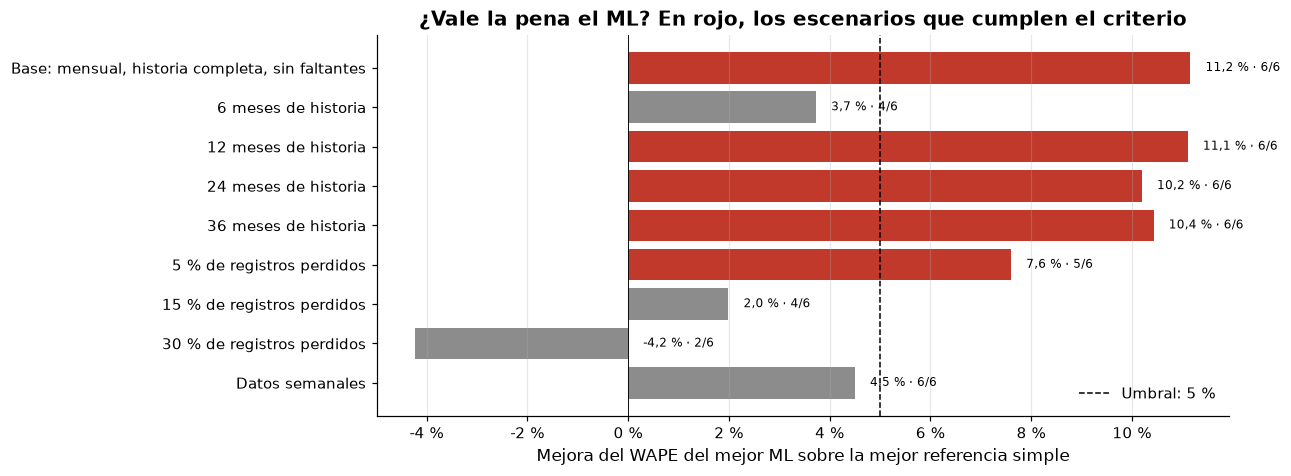

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["#c0392b" if v else "#8c8c8c" for v in criterio["vale_la_pena"]]
ax.barh(criterio["escenario"], criterio["mejora"], color=colores)
ax.axvline(cfg.UMBRAL_MEJORA_ML, color="black", ls="--", lw=1, label=f"Umbral: {G.pct(cfg.UMBRAL_MEJORA_ML, 0)}")
ax.axvline(0, color="black", lw=0.6)
for i, (v, g) in enumerate(zip(criterio["mejora"], criterio["ganados"])):
    # Las etiquetas van siempre a la derecha del cero, para no pisar los nombres del eje.
    ax.text(max(v, 0) + 0.003, i, f"{G.pct(v)} · {g}/{len(cfg.MESES_EXPERIMENTO)}", va="center", ha="left", fontsize=8)
ax.invert_yaxis()
G.porcentaje(ax, "x")
ax.set_xlabel("Mejora del WAPE del mejor ML sobre la mejor referencia simple")
ax.set_title("¿Vale la pena el ML? En rojo, los escenarios que cumplen el criterio")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
G.guardar(fig, "03_criterio")
plt.show()

## 8. La respuesta a la pregunta

El texto se arma con las cifras del experimento, sin números escritos a mano: si se vuelve a
correr con otros datos, la respuesta se actualiza sola.

In [16]:
c = criterio
niveles = list(zip(ids_hist, cfg.HISTORIAS_MESES + [None]))
pasan = [bool(c.loc[i, "vale_la_pena"]) for i, _ in niveles]
desde = next((k for k in range(len(niveles)) if all(pasan[k:])), None)

print("HISTORIZACIÓN")
if desde is None:
    print("  En ningún nivel de historia el ML supera el criterio de forma estable.")
elif niveles[desde][1] is None:
    print("  El ML solo supera el criterio con la historia completa (cuatro años o más).")
else:
    print(f"  El ML supera el criterio desde {niveles[desde][1]} meses de historia y en todos los niveles mayores.")
for i, h in niveles:
    etiqueta = f"{h} meses" if h else "completa"
    print(f"  · {etiqueta}: {c.loc[i, 'mejor_ml']} {G.pct(c.loc[i, 'mejora'])} sobre {c.loc[i, 'mejor_referencia']}, {c.loc[i, 'ganados']}/{len(cfg.MESES_EXPERIMENTO)} meses → {'sí' if c.loc[i, 'vale_la_pena'] else 'no'}")

print("\nCALIDAD")
for f in cfg.FALTANTES:
    i = f"faltantes_{round(f * 100)}"
    r = res[res["escenario"] == i].set_index("modelo")
    print(f"  · {G.pct(f, 0)} perdido: sesgo de {c.loc[i, 'mejor_ml']} {G.pct(r.loc[c.loc[i, 'mejor_ml'], 'sesgo'])}, "
          f"el error sube {G.puntos(costo_faltantes[f])}, ML {'vale' if c.loc[i, 'vale_la_pena'] else 'no vale'} la pena")
# Según el criterio: la mayor pérdida con la que el ML todavía vale la pena, y la primera con la que no.
tolera = [f for f in cfg.FALTANTES if c.loc[f"faltantes_{round(f * 100)}", "vale_la_pena"]]
no_tolera = [f for f in cfg.FALTANTES if not c.loc[f"faltantes_{round(f * 100)}", "vale_la_pena"]]
if not no_tolera:
    calidad_txt = f"aun perdiendo el {G.pct(max(cfg.FALTANTES), 0)} de los registros el ML sigue valiendo la pena"
elif not tolera:
    calidad_txt = f"con apenas un {G.pct(min(cfg.FALTANTES), 0)} de registros perdidos el ML ya no vale la pena"
else:
    calidad_txt = (
        f"con un {G.pct(max(tolera), 0)} de registros perdidos el ML todavía vale la pena, "
        f"con un {G.pct(min(no_tolera), 0)} ya no"
    )
print(f"  Con datos completos el ML quita {G.puntos(ganancia_ml)} de WAPE; {calidad_txt}.")

print("\nFRECUENCIA")
mejor_mensual, mejor_semanal = c.loc["base", "wape_ml"], c.loc["semanal", "wape_ml"]
semanal_mejora = mejor_semanal < mejor_mensual
print(f"  Mejor ML mensual {G.pct(mejor_mensual)} · mejor ML con datos semanales {G.pct(mejor_semanal)}: "
      f"{'los datos semanales mejoran' if semanal_mejora else 'los datos semanales no mejoran'} el pronóstico del mes.")

# Cuánto de la mejora del ML sobre el naive estacional ya consigue la media móvil.
est, media, ml = base.loc["Naive estacional", "wape"], base.loc[MEDIA, "wape"], base.loc[ML, "wape"].min()
captura_media = (est - media) / (est - ml)
print(f"\nREFERENCIA SIMPLE\n  La media móvil de {K_MEDIA} meses ya consigue el {G.pct(captura_media, 0)} de la mejora que logra el ML sobre el naive estacional.")

HISTORIZACIÓN
  El ML supera el criterio desde 12 meses de historia y en todos los niveles mayores.
  · 6 meses: LightGBM 3,7 % sobre Media móvil 12m, 4/6 meses → no
  · 12 meses: LightGBM 11,1 % sobre Media móvil 12m, 6/6 meses → sí
  · 24 meses: LightGBM 10,2 % sobre Media móvil 12m, 6/6 meses → sí
  · 36 meses: LightGBM 10,4 % sobre Media móvil 12m, 6/6 meses → sí
  · completa: LightGBM 11,2 % sobre Media móvil 12m, 6/6 meses → sí

CALIDAD
  · 5 % perdido: sesgo de LightGBM -12,7 %, el error sube 0,5 puntos, ML vale la pena
  · 15 % perdido: sesgo de LightGBM -22,8 %, el error sube 3,5 puntos, ML no vale la pena
  · 30 % perdido: sesgo de Ridge -29,6 %, el error sube 10,3 puntos, ML no vale la pena
  Con datos completos el ML quita 4,3 puntos de WAPE; con un 5 % de registros perdidos el ML todavía vale la pena, con un 15 % ya no.

FRECUENCIA
  Mejor ML mensual 34,1 % · mejor ML con datos semanales 35,6 %: los datos semanales no mejoran el pronóstico del mes.

REFERENCIA SIMPLE
  La 

In [17]:
h_min = niveles[desde][1] if desde is not None else None
historia_txt = (
    f"al menos {h_min} meses de historia continua" if h_min
    else "la historia completa de varios años" if desde is not None
    else "más historia de la que tiene este dataset"
)
import textwrap

frecuencia_txt = (
    "registrar por semana mejora un poco el pronóstico del mes, así que conviene si ya se tiene"
    if semanal_mejora
    else "registrar por semana no mejora el pronóstico del mes: alcanza con la frecuencia de la decisión"
)
parrafos = [
    f"COMERCIAL. En este dataset, una empresa puede pasar de BI a ML de demanda cuando tiene {historia_txt} "
    f"y registra prácticamente todas sus ventas: {calidad_txt}. En frecuencia, {frecuencia_txt}, que para "
    f"planificar producción es mensual. Por debajo de eso, la mejor herramienta es una media móvil bien elegida, "
    f"que ya consigue el {G.pct(captura_media, 0)} de la mejora del ML sobre el naive estacional.",
    "OPERATIVA. Para predecir fallas el paso previo es medir la planta: sensores y un registro de cada falla. "
    "Sin eso, el nivel alcanzable es el mantenimiento preventivo. El anexo del notebook 02 muestra por qué, "
    "con eventos raros, el accuracy no sirve para evaluar.",
    "HERRAMIENTAS. Todo el camino se hizo sin licencias: Python, pandas, scikit-learn, LightGBM y statsforecast, "
    "en Colab o Jupyter. Para ver los datos, Looker Studio, Metabase o Superset tampoco cobran licencia. El costo "
    "real no es el software: es la persona que sabe usarlo y el registro disciplinado de los datos.",
]
respuesta = "\n\n".join(textwrap.fill(p, 100) for p in parrafos)
print(respuesta)
(cfg.TABLAS / "respuesta_pregunta.txt").write_text(respuesta + "\n", encoding="utf-8")

COMERCIAL. En este dataset, una empresa puede pasar de BI a ML de demanda cuando tiene al menos 12
meses de historia continua y registra prácticamente todas sus ventas: con un 5 % de registros
perdidos el ML todavía vale la pena, con un 15 % ya no. En frecuencia, registrar por semana no
mejora el pronóstico del mes: alcanza con la frecuencia de la decisión, que para planificar
producción es mensual. Por debajo de eso, la mejor herramienta es una media móvil bien elegida, que
ya consigue el 77 % de la mejora del ML sobre el naive estacional.

OPERATIVA. Para predecir fallas el paso previo es medir la planta: sensores y un registro de cada
falla. Sin eso, el nivel alcanzable es el mantenimiento preventivo. El anexo del notebook 02 muestra
por qué, con eventos raros, el accuracy no sirve para evaluar.

HERRAMIENTAS. Todo el camino se hizo sin licencias: Python, pandas, scikit-learn, LightGBM y
statsforecast, en Colab o Jupyter. Para ver los datos, Looker Studio, Metabase o Superset tampoc

1123

### Límites del experimento

- **Un solo dataset.** Las cifras son de un fabricante con este perfil de demanda: muchos pedidos
  por serie, un depósito dominante y mucho ruido mensual. Otro rubro puede dar otros umbrales.
- **Pérdida al azar.** Es el caso más benigno. Una pérdida concentrada en un depósito o un período
  sesga más.
- **La historia recortada no crea productos nuevos.** Simula una empresa que empezó a registrar
  hace poco, no un catálogo nuevo.
- **Seis orígenes.** Alcanzan para ver la dispersión, pero un efecto chico puede cambiar de signo
  con otros meses. Por eso el criterio pide ganar en al menos 4 de 6 y no solo en promedio.
- **Cómo validarlo en una empresa real:** usar el modelo en paralelo con el método actual durante
  varios meses (un piloto) y comparar errores y quiebres antes de reemplazar nada.